In [1]:
import pandas as pd
import numpy as np

In [2]:
# Every displayed hit rate (0-100) and every possible random number (0-99).
displayed = np.arange(101)
rn = np.arange(100)

# One RN: roll one number 0-99; the attack lands if it is less than the displayed hit.
# Shape (101, 100): one row per displayed hit, one column per possible roll.
one_rn_hits = rn[None, :] < displayed[:, None]
one_rn = one_rn_hits.mean(axis=1) * 100

# True hit (2 RN): roll two numbers 0-99; the attack lands if their average is less than the displayed hit.
# All 100 x 100 roll pairs are equally likely, so the hit rate is the share of pairs that land.
avg = (rn[:, None] + rn[None, :]) / 2 # shape (100, 100)
true_hit_hits = avg[None, :, :] < displayed[:, None, None]  # shape (101, 100, 100)
true_hit = true_hit_hits.mean(axis=(1, 2)) * 100

# Hybrid: one RN below 50 displayed hit; otherwise
#   (Hit × 100) + (40 / 3) × Hit × sin((0.02 × Hit − 1) × 180°)
# That formula is out of 10,000, so divide by 100 to get a percent. The angle is in degrees.
angle = np.deg2rad((0.02 * displayed - 1) * 180)
hybrid_formula = (displayed * 100 + (40 / 3) * displayed * np.sin(angle)) / 100
hybrid = np.where(displayed < 50, one_rn, hybrid_formula)

In [3]:
df = pd.DataFrame({"displayed": displayed, "one_rn": one_rn, "true_hit": true_hit, "hybrid": hybrid})
df.iloc[40:60]

,displayed,one_rn,true_hit,hybrid
40,40,40.0,32.40,40.000000
41,41,41.0,34.03,41.000000
42,42,42.0,35.70,42.000000
43,43,43.0,37.41,43.000000
44,44,44.0,39.16,44.000000
45,45,45.0,40.95,45.000000
46,46,46.0,42.78,46.000000
47,47,47.0,44.65,47.000000
48,48,48.0,46.56,48.000000
49,49,49.0,48.51,49.000000


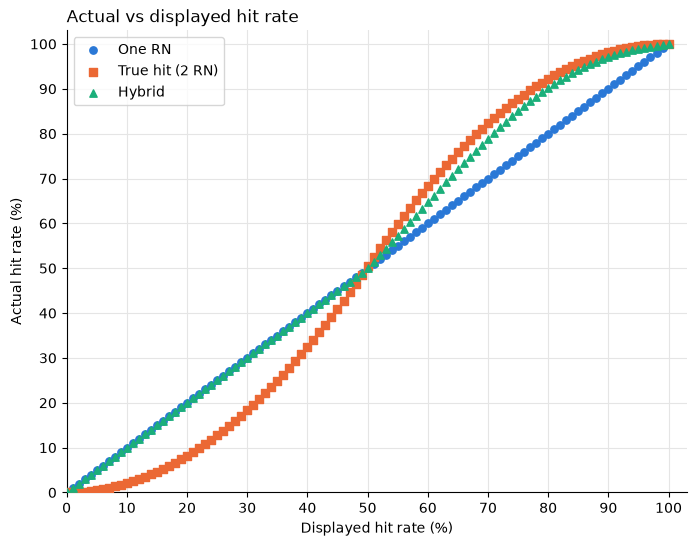

In [4]:
import matplotlib.pyplot as plt

# One colour and one marker shape per system, so they stay distinguishable without colour.
# Below 50, hybrid equals one RN, so its triangles sit on top of the one-RN circles.
systems = [
    ("one_rn", "One RN", "#2a78d6", "o"),
    ("true_hit", "True hit (2 RN)", "#eb6834", "s"),
    ("hybrid", "Hybrid", "#1baf7a", "^"),
]

plt.figure(figsize=(8, 6))
for column, label, color, marker in systems:
    plt.scatter(df["displayed"], df[column], label=label, color=color, marker=marker,
                s=28, zorder=3)

plt.title("Actual vs displayed hit rate", loc="left")
plt.xlabel("Displayed hit rate (%)")
plt.ylabel("Actual hit rate (%)")
# Pad the limits past 0 and 100 so markers on the edges aren't cut off.
plt.xlim(0, 103)
plt.ylim(0, 103)
plt.xticks(range(0, 101, 10))
plt.yticks(range(0, 101, 10))
plt.grid(color="#e5e5e5", linewidth=0.8, zorder=0)
for side in ("top", "right"):
    plt.gca().spines[side].set_visible(False)
plt.legend(loc="upper left")
plt.show()

In [5]:
(df["displayed"] - df["true_hit"]).idxmax()

25

In [6]:
(df["true_hit"] - df["displayed"]).idxmax()

75

#### Experiment: Displayed 24% hit chance



In [7]:
n_attacks_24 = 150
n_hits_24 = 37
actual_hit_24 = n_hits_24 / n_attacks_24

# Bootstrap: resample 150 attacks with replacement, 10,000 times.
# For hit/miss data, resampling the 150 outcomes is the same as drawing
# Binomial(150, observed rate), so each draw is one resample's hit count.
rng = np.random.default_rng(0)
boot_rates = rng.binomial(n_attacks_24, actual_hit_24, size=10_000) / n_attacks_24 * 100

ci_low, ci_high = np.percentile(boot_rates, [2.5, 97.5])
print(f"Observed: {actual_hit_24 * 100:.2f}%  95% CI: {ci_low:.2f}% to {ci_high:.2f}%")

# Which systems' predicted rate at displayed 24 falls inside the interval?
predicted_24 = df.loc[df["displayed"] == 24, ["one_rn", "true_hit", "hybrid"]].iloc[0]
pd.DataFrame({
    "predicted": predicted_24,
    "inside_95_ci": (predicted_24 >= ci_low) & (predicted_24 <= ci_high),
})

Observed: 24.67%  95% CI: 18.00% to 32.00%


,predicted,inside_95_ci
one_rn,24.00,True
true_hit,11.76,False
hybrid,24.00,True


##### Calculating p-value under 2-rn

In [8]:
from math import comb

n = n_attacks_24
p = df.loc[df["displayed"] == 24, "true_hit"].iloc[0] / 100

# Probability of exactly k hits, for k = 0..n
pmf = np.array([comb(n, k) * p**k * (1 - p)**(n - k) for k in range(n + 1)])
cdf = pmf.cumsum()

# 95% range: smallest k where the running total reaches 2.5%, and where it reaches 97.5%
lo = np.searchsorted(cdf, 0.025)
hi = np.searchsorted(cdf, 0.975)
print(f"95% range under true hit of displayed 24%: {lo}-{hi} hits ({lo / n * 100:.2f}% to {hi / n * 100:.2f}%)")

# p-value: chance of 37 or more hits if true hit were the real system
p_value = pmf[37:].sum()
print(f"P(at least 37 hits | true hit) = {p_value:.2e}")

95% range under true hit of displayed 24%: 10-26 hits (6.67% to 17.33%)
P(at least 37 hits | true hit) = 8.88e-06


#### Experiment: Displayed 78% hit chance

In [9]:
n_attacks_78 = 150
n_hits_78 = 134
actual_hit_78 = n_hits_78 / n_attacks_78

# Bootstrap: resample 150 attacks with replacement, 10,000 times.
# For hit/miss data, resampling the 150 outcomes is the same as drawing
# Binomial(150, observed rate), so each draw is one resample's hit count.
rng = np.random.default_rng(0)
boot_rates = rng.binomial(n_attacks_78, actual_hit_78, size=10_000) / n_attacks_78 * 100

ci_low, ci_high = np.percentile(boot_rates, [2.5, 97.5])
print(f"Observed: {actual_hit_78 * 100:.2f}%  95% CI: {ci_low:.2f}% to {ci_high:.2f}%")

# Which systems' predicted rate at displayed 78 falls inside the interval?
predicted_78 = df.loc[df["displayed"] == 78, ["one_rn", "true_hit", "hybrid"]].iloc[0]
pd.DataFrame({
    "predicted": predicted_78,
    "inside_95_ci": (predicted_78 >= ci_low) & (predicted_78 <= ci_high),
})

Observed: 89.33%  95% CI: 84.00% to 94.00%


,predicted,inside_95_ci
one_rn,78.000000,False
true_hit,90.540000,True
hybrid,88.215787,True
